In [1]:
import matplotlib.pyplot as plt
import numpy as np
from itertools import product, count
import math
import cmath

In [2]:
def exactharm(R, r, x0):
    "Compute the exact h function h(r) for the circle of radius R with base point x0 (assumed real)"
    sR = 1
    sr = r/R
    sx0 = x0/R
    if abs(sx0) + sr <= 1:
        return 0
    if 1 + abs(sx0) <= sr:
        return 1
    costheta = (sr**2 - 1 - sx0**2) / (-2*sx0)
    sintheta = math.sqrt(1-costheta**2)
    bz = costheta + 1j*sintheta
    newz = (bz-sx0)*(1-1/sx0)/((bz-1/sx0)*(1-sx0))
    return cmath.phase(newz) / math.pi

In [3]:
def circleverts(radius):
    """Returns list of interior point coordinates and a list of boundary point coordinates"""
    inner = []
    boundary = []
    for (x,y) in product(range(math.ceil(-radius-1),math.ceil(radius+1.01)), range(math.ceil(-radius-1),math.ceil(radius+1.01))):
        if x*x+y*y < radius*radius:
            inner.append((x,y))
        else:
            # 0.8 is a bit arbitrary, chosen to lazily remove unreachable bdy points when R=10
            if x*x+y*y < (radius+0.8)*(radius+0.8): 
                boundary.append((x,y))
    return inner, boundary

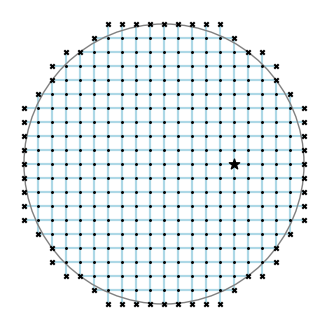

In [4]:
R = 10

interior, boundary = circleverts(R)
ix = [x for (x,y) in interior]
iy = [y for (x,y) in interior]
bx = [x for (x,y) in boundary]
by = [y for (x,y) in boundary]

dR = lambda m : [x/R for x in m]

plt.axes().set_aspect('equal')
plt.gcf().set_size_inches(4,4)
intset = set(interior)
bdyset = set(boundary)
for (x,y) in interior:
    #print(x,y)
    inbrs = []
    bnbrs = []
    for (nx,ny) in [(x-1,y), (x+1,y), (x,y-1), (x,y+1)]:
        if (nx, ny) in bdyset:
            plt.plot([x/R,nx/R],[y/R,ny/R],color='lightblue')
            #bnbrs.append(bdyidx[(nx, ny)])
        if (nx, ny) in intset:
            plt.plot([x/R,nx/R],[y/R,ny/R],color='lightblue')
            #inbrs.append(intidx[(nx, ny)])

plt.axis('off')
circle = plt.Circle((0,0), 1.0, color='grey', fill=False,zorder=2)
plt.gca().add_patch(circle)
plt.scatter(dR(ix), dR(iy), color='black', marker='.', s=5,zorder=3)
plt.scatter(dR(bx), dR(by), color='black', marker='x', s=10, label='Boundary',zorder=4)
plt.scatter(0.5,0, marker='*', s=60, color='black',zorder=3) #, facecolors='none', edgecolors='blue')
#plt.legend()
#plt.savefig('circlegridnoaxes0.1v2.pdf')


In [5]:
def buildmatrix(boundary, interior):
    """from list of boundary coordinates and interior coordinates, build the transistion matrix,
    assuming boundary points are absorbing.  Follows the procedure in Snell and Doyle."""
    u = len(boundary)
    v = len(interior)
    R = np.zeros((v, u))
    Q = np.zeros((v, v))
    intidx = dict(zip(interior, count()))
    bdyidx = dict(zip(boundary, count()))
    for (x,y) in interior:
        #print(x,y)
        inbrs = []
        bnbrs = []
        for (nx,ny) in [(x-1,y), (x+1,y), (x,y-1), (x,y+1)]:
            if (nx, ny) in bdyidx:
                bnbrs.append(bdyidx[(nx, ny)])
            if (nx, ny) in intidx:
                inbrs.append(intidx[(nx, ny)])
        tnbrs = len(inbrs) + len(bnbrs)
        for nidx in bnbrs:
            R[intidx[(x,y)], nidx] += 1/tnbrs
        for nidx in inbrs:
            Q[intidx[(x,y)], nidx] += 1/tnbrs
    #B = np.matmul(np.linalg.inv(np.eye(v)-Q), R) # as in Snell and Doyle, but...
    B = np.linalg.solve(np.eye(v)-Q, R)           # this is better
    return B

In [6]:
%%time
B=buildmatrix(boundary, interior)

CPU times: user 3.75 ms, sys: 1.34 ms, total: 5.08 ms
Wall time: 3.97 ms


In [8]:
intidx = dict(zip(interior, count()))
bdyidx = dict(zip(boundary, count()))

basex = R // 2 # 20
basept = (-basex,0)
baseidx = intidx[basept]

dists = np.sqrt((np.array(bx) - basept[0]) ** 2 + (np.array(by) - basept[1])**2)

r = np.linspace(0,2*R,400)
harm = r*0
for i in range(len(r)):
    harm[i] = np.dot(B[baseidx], dists < r[i])

xharm = r*0
for i in range(len(r)):
    xharm[i] = exactharm(R, r[i], basex)
    #print(r[i], xharm[i], R, basex)


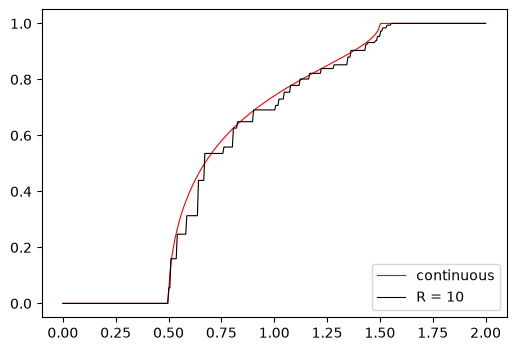

In [9]:
sr = r/R
plt.gcf().set_size_inches(6,4)
plt.plot(sr, xharm, color = 'red',  lw=0.8, label='continuous')
plt.plot(sr,harm, color='black', lw=0.8, label=f"R = {R}")
plt.legend(loc='lower right')
#plt.plot(r, xharm)
#plt.savefig('harm60.pdf')